<a href="https://colab.research.google.com/github/marpablo/Marian_INFO4670_Fall2026/blob/main/INFO_4670_Assignment_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 5

Name: Marian Pablo

Date: October 26, 2026

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
print('Setup complete!')


Setup complete!


# Step 1 - Define the Problem

Q1a.

A false positive is more costly in a real spam filter. An example of a false positive is when a user doesn't recieve the necessary notification for bank verification. As for a false negative, this occurs when the user receives an unwanted promotional notification. This is why a false positive is more costly. It can prevent someone accessing their account sine they will be missing the necessary verification.

Q1b.

Because of Q1a, precision should be the primary evaluation target. Maximizing precision minimizes false positives and ensurses the necessary alerts are received.

Q1c.

A dummy model that always predicts "ham" would achieve 87% accuracy. This number is misleading because 87% of the messages are actually ham. And it fails to catch actual spam messages (0) making it a non working spam filter.

# Step 2 - Load and Explore the Data

Step 2A

In [ ]:
import urllib.request, zipfile, io

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
print('Downloading UCI SMS Spam Collection...')
with urllib.request.urlopen(url) as r:
    zf = zipfile.ZipFile(io.BytesIO(r.read()))
    with zf.open('SMSSpamCollection') as f:
        raw = pd.read_csv(f, sep='\t', header=None, names=['label', 'message'])

raw['spam'] = (raw['label'] == 'spam').astype(int)
print(f'Loaded: {len(raw)} messages')
raw.head(6)

Loaded: 5572 messages


,label,message,spam
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0
5,spam,FreeMsg Hey there darling it's been 3 week's n...,1


Step 2B

Class distribution:
  Ham  (0): 4,825  (86.6%)
  Spam (1): 747  (13.4%)

Dummy model (always predict ham):
  Accuracy  = 86.6%  <-- misleadingly high
  Recall    = 0.0%  <-- catches zero spam
  F1-Score  = 0.0%


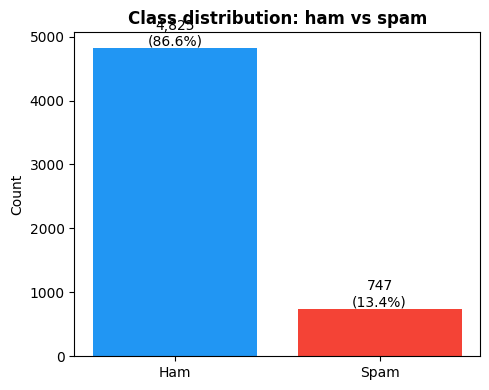

In [ ]:
ham_count  = (raw['spam'] == 0).sum()
spam_count = (raw['spam'] == 1).sum()
spam_rate  = raw['spam'].mean()

print('Class distribution:')
print(f'  Ham  (0): {ham_count:,}  ({1-spam_rate:.1%})')
print(f'  Spam (1): {spam_count:,}  ({spam_rate:.1%})')
print()

y_all   = raw['spam'].values
y_dummy = np.zeros(len(y_all), dtype=int)
print(f'Dummy model (always predict ham):')
print(f'  Accuracy  = {accuracy_score(y_all, y_dummy):.1%}  <-- misleadingly high')
print(f'  Recall    = {recall_score(y_all, y_dummy, zero_division=0):.1%}  <-- catches zero spam')
print(f'  F1-Score  = {f1_score(y_all, y_dummy, zero_division=0):.1%}')

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['Ham', 'Spam'], [ham_count, spam_count], color=['#2196F3', '#F44336'])
ax.set_ylabel('Count')
ax.set_title('Class distribution: ham vs spam', fontweight='bold')
for i, v in enumerate([ham_count, spam_count]):
    ax.text(i, v + 30, f'{v:,}\n({v/len(raw):.1%})', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

Step 2C

In [ ]:
print('=== SPAM examples ===')
for i, msg in enumerate(raw[raw['spam']==1]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()

print('=== HAM examples ===')
for i, msg in enumerate(raw[raw['spam']==0]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()

=== SPAM examples ===
1. Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's 

2. FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to s

3. WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code 

4. Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Updat

5. SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 

=== HAM examples ===
1. Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

2. Ok lar... Joking wif u oni...

3. U dun say so early hor... U c already then say...

4. Nah I don't think he goes to usf, he lives around here though

5. Even my b

Step 2D

Average message length:
  Ham  : 71 characters
  Spam : 139 characters


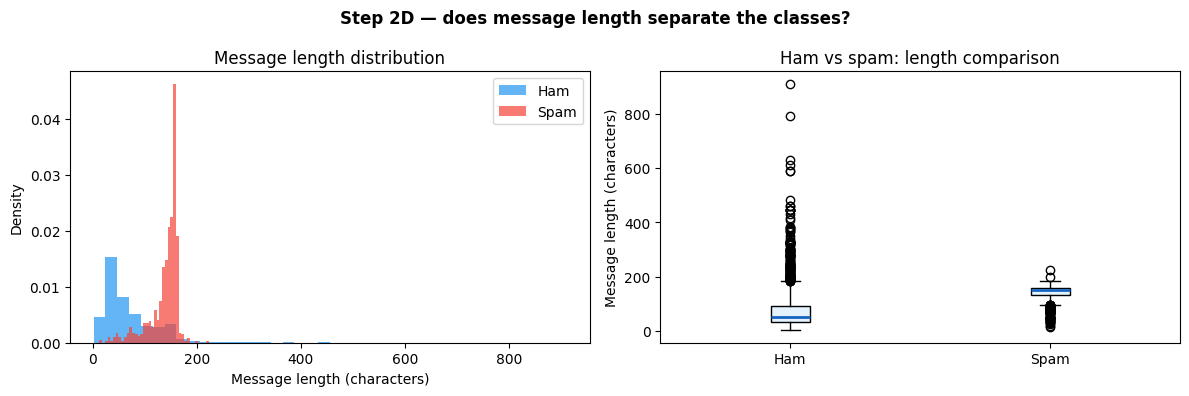

In [ ]:
raw['msg_length'] = raw['message'].str.len()

print('Average message length:')
print(f'  Ham  : {raw[raw["spam"]==0]["msg_length"].mean():.0f} characters')
print(f'  Spam : {raw[raw["spam"]==1]["msg_length"].mean():.0f} characters')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(raw[raw['spam']==0]['msg_length'], bins=40, alpha=0.7,
             color='#2196F3', label='Ham', density=True)
axes[0].hist(raw[raw['spam']==1]['msg_length'], bins=40, alpha=0.7,
             color='#F44336', label='Spam', density=True)
axes[0].set_xlabel('Message length (characters)')
axes[0].set_ylabel('Density')
axes[0].set_title('Message length distribution')
axes[0].legend()

axes[1].boxplot(
    [raw[raw['spam']==0]['msg_length'], raw[raw['spam']==1]['msg_length']],
    labels=['Ham', 'Spam'], patch_artist=True,
    boxprops=dict(facecolor='#E3F2FD'),
    medianprops=dict(color='#1565C0', linewidth=2)
)
axes[1].set_ylabel('Message length (characters)')
axes[1].set_title('Ham vs spam: length comparison')
plt.suptitle('Step 2D — does message length separate the classes?', fontweight='bold')
plt.tight_layout()
plt.show()

# Step 3 - Feature Engineering

Step 3A

In [ ]:
def build_features(df):
    d = df.copy()
    msg = d['message'].str.lower()

    d['has_phone'] = msg.str.contains(
        r'\b\d{3}[-.]?\d{3}[-.]?\d{4}\b|call.*\d{4,}|\b0\d{9,}\b',
        regex=True).astype(int)

    d['has_money'] = msg.str.contains(
        r'\b(free|win|winner|prize|cash|\$|claim|reward|won)\b',
        regex=True).astype(int)

    d['has_urgency'] = msg.str.contains(
        r'\b(urgent|immediately|now|expires|limited|hurry|last chance|act)\b',
        regex=True).astype(int)

    d['is_long'] = (d['message'].str.len() > 130).astype(int)
    return d

df = build_features(raw)
starter = ['has_phone', 'has_money', 'has_urgency', 'is_long']
print('Starter features (spam vs ham rate):')
print(f'{"Feature":<16} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 42)
for f in starter:
    sp = df[df['spam']==1][f].mean()
    ha = df[df['spam']==0][f].mean()
    print(f'{f:<16} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')

Starter features (spam vs ham rate):
Feature            Spam%    Ham%     Gap
------------------------------------------
has_phone          55.2%    0.1%  +55.1%
has_money          52.3%    2.0%  +50.3%
has_urgency        34.9%    6.4%  +28.5%
is_long            76.8%   14.2%  +62.7%


Step 3B

In [ ]:
def build_features_v2(df):
    d = build_features(df)
    msg = d['message'].str.lower()

    d['has_url'] = msg.str.contains(r'https?://|www\.|\.com', regex=True).astype(int)


    d['has_cta'] = msg.str.contains(r'\b(txt|text|reply|stop)\b', regex=True).astype(int)

    return d

df = build_features_v2(raw)

# Collect all feature column names — DO NOT delete this line
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]

print('All features (spam vs ham rate):')
print(f'{"Feature":<20} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 48)
for feat in feature_cols:
    sp = df[df['spam']==1][feat].mean()
    ha = df[df['spam']==0][feat].mean()
    print(f'{feat:<20} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')

All features (spam vs ham rate):
Feature                Spam%    Ham%     Gap
------------------------------------------------
has_phone              55.2%    0.1%  +55.1%
has_money              52.3%    2.0%  +50.3%
has_urgency            34.9%    6.4%  +28.5%
is_long                76.8%   14.2%  +62.7%
has_url                16.2%    0.3%  +15.9%
has_cta                44.6%    3.2%  +41.4%


Step 3C

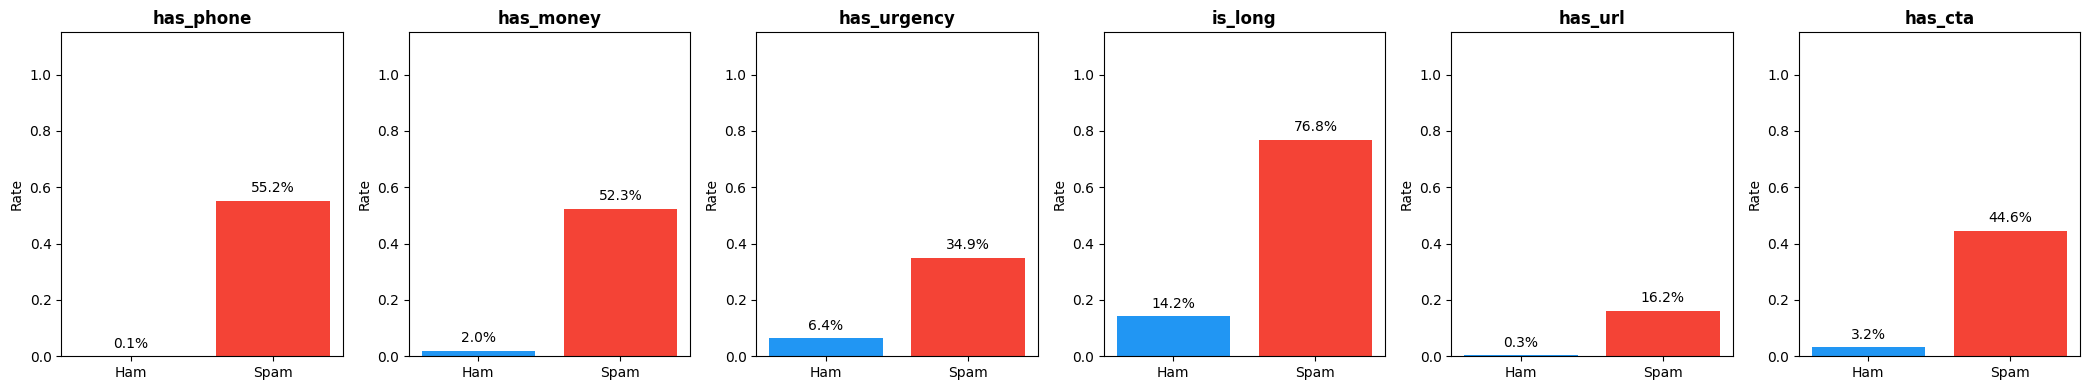

In [ ]:
n_feats = len(feature_cols)
fig, axes = plt.subplots(1, n_feats, figsize=(3.5 * n_feats, 4))

for i, feat in enumerate(feature_cols):
    ham_rate = df[df['spam'] == 0][feat].mean()
    spam_rate = df[df['spam'] == 1][feat].mean()

    ax = axes[i]
    ax.bar(['Ham', 'Spam'], [ham_rate, spam_rate], color=['#2196F3', '#F44336'])
    ax.set_ylabel('Rate')
    ax.set_title(feat, fontweight='bold')
    ax.set_ylim(0, 1.15)

    for idx, v in enumerate([ham_rate, spam_rate]):
        ax.text(idx, v + 0.03, f'{v:.1%}', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

Q3a.

Feature 1 -

Name: has_url

Explanation: This feature capturess web hyperlinks, domain patterns, prefixes/sufixes. It is an effective method to capture a spam signal as scammers can forward users to suspicious links.

Feature 2 -

Name: has_cta

Explanation: This feature captures mobile call-to-action keywords. It is an effective method to reduce automated marketing texts.

Q3b.

The feature with the largest gap between spam and ham is has_phone. This is important as a decision tree splits points. When a a large separation occurs, two nodes are created (one with spam and the other with pure ham). The decision tree will then pick the feature that has the highest information gain.

Q3c.

One example my features would fail to catch is a message that seems conversational. For example, "Your account was logged into from a new device in Dallas. Confirm if this was you." The has_url would fail as it includes zero web links. has_phone would fail as there are no phone numbers involved. has_money fails as there's no cash words, has_urgency would fail as there is no urgency, is_long fails as the message is under 130 characters, and has_cta fails as there are no command words. As a result, "Your account was logged into from a new device in Dallas. Confirm if this was you" would be able to slip through as a false negative.

# Step 4 - Split the Data

In [ ]:
X = df[feature_cols].values
y = df['spam'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print(f"Train size: {len(y_train):,} samples | Spam rate: {y_train.mean():.2%}")
print(f"Test size:  {len(y_test):,} samples | Spam rate: {y_test.mean():.2%}")

Train size: 4,179 samples | Spam rate: 13.40%
Test size:  1,393 samples | Spam rate: 13.42%


Q4a.

We pass stratify=y to ensure the original class distribution is preserved across the training and test sets.

As the dataset is imbalanced, skipping the stratification step will cause random splits and be disproportionate. Then, the model will not have enough examples to learn and have effective boundaries when it comes to detecting spam.

Q4b.

One situtaion where you would prefer cross-validation over a single split is with a small dataset.

A small dataset with 25% of the data being set aside doesn't leave enough examples. As a result, using cross-validation will ensure that each data point is used in a balance way.


# Step 5 - Train The Models

Step 5A

Number of leaves: 14


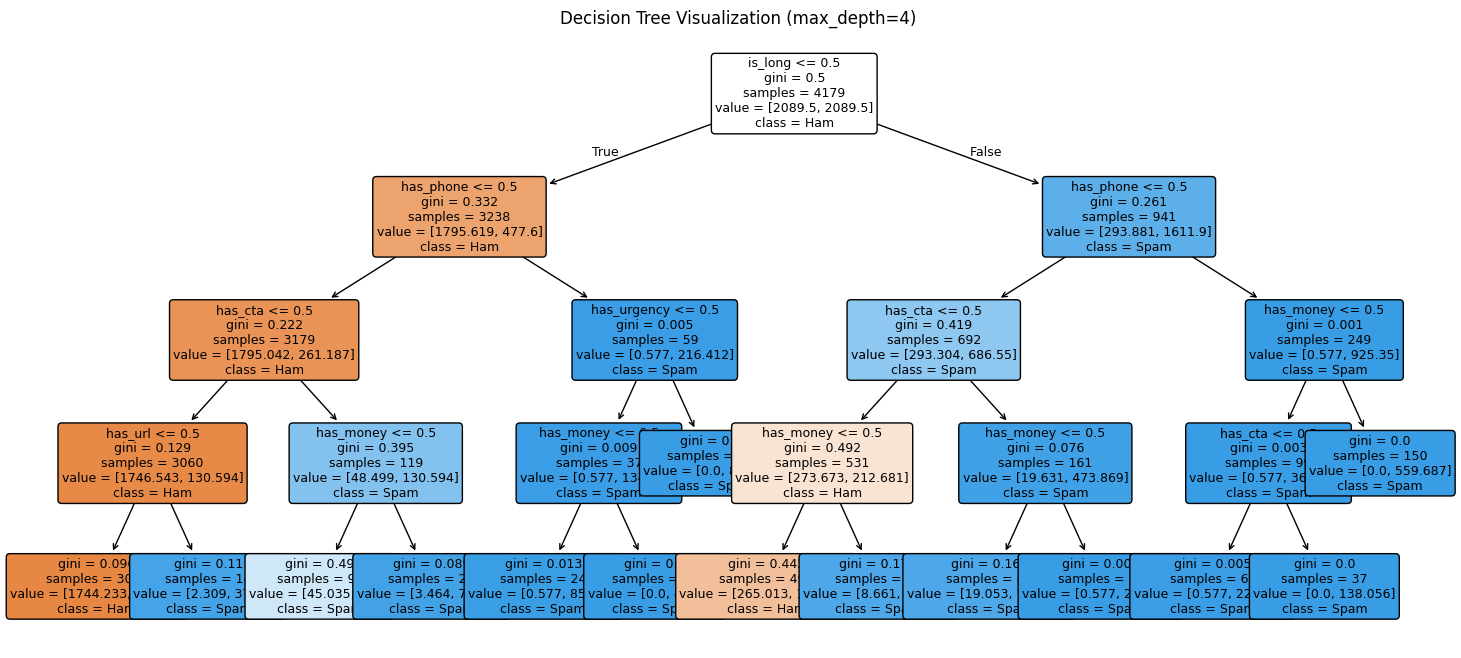


--- Decision Tree Rules ---

|--- is_long <= 0.50
|   |--- has_phone <= 0.50
|   |   |--- has_cta <= 0.50
|   |   |   |--- has_url <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- has_url >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_cta >  0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |--- has_phone >  0.50
|   |   |--- has_urgency <= 0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_urgency >  0.50
|   |   |   |--- class: 1
|--- is_long >  0.50
|   |--- has_phone <= 0.50
|   |   |--- has_cta <= 0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_cta >  0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- cl

In [ ]:
dt = DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')
dt.fit(X_train, y_train)

print(f"Number of leaves: {dt.get_n_leaves()}")

plt.figure(figsize=(18, 8))
plot_tree(
    dt,
    feature_names=feature_cols,
    class_names=['Ham', 'Spam'],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Decision Tree Visualization (max_depth=4)")
plt.show()

tree_rules = export_text(dt, feature_names=feature_cols)
print("\n--- Decision Tree Rules ---\n")
print(tree_rules)

Step 5B

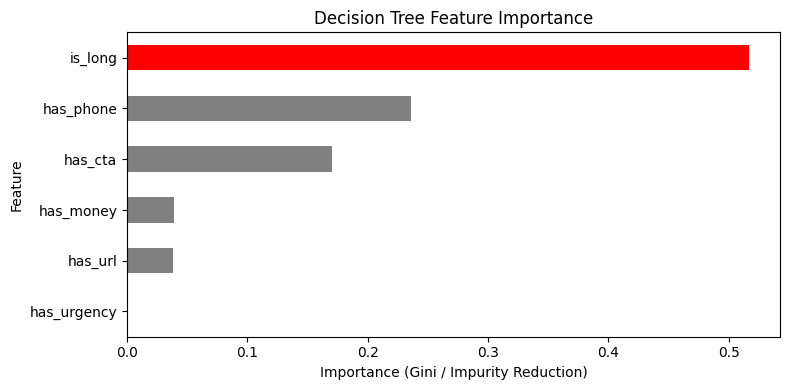

Feature Importances:
is_long        0.516755
has_phone      0.235784
has_cta        0.170372
has_money      0.039111
has_url        0.037977
has_urgency    0.000001
dtype: float64


In [ ]:
importances = pd.Series(dt.feature_importances_, index=feature_cols).sort_values(ascending=True)

colors = ['gray' if val != importances.max() else 'red' for val in importances]

plt.figure(figsize=(8, 4))
importances.plot(kind='barh', color=colors)

plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance (Gini / Impurity Reduction)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("Feature Importances:")
print(importances.sort_values(ascending=False))

Step 5C

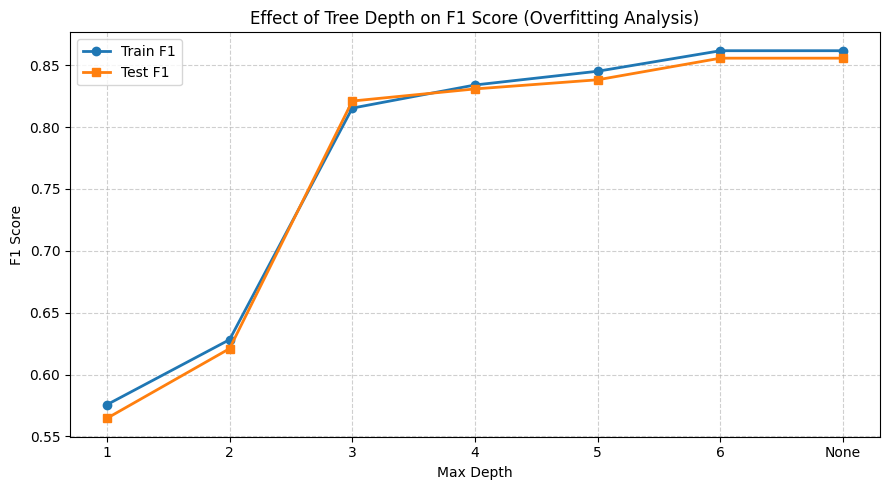

Depth    1: Train F1 = 0.5756 | Test F1 = 0.5646 | Gap = 0.0110
Depth    2: Train F1 = 0.6282 | Test F1 = 0.6210 | Gap = 0.0073
Depth    3: Train F1 = 0.8153 | Test F1 = 0.8211 | Gap = -0.0057
Depth    4: Train F1 = 0.8340 | Test F1 = 0.8308 | Gap = 0.0032
Depth    5: Train F1 = 0.8451 | Test F1 = 0.8382 | Gap = 0.0069
Depth    6: Train F1 = 0.8617 | Test F1 = 0.8557 | Gap = 0.0060
Depth None: Train F1 = 0.8617 | Test F1 = 0.8557 | Gap = 0.0060


In [ ]:
depths = [1, 2, 3, 4, 5, 6, None]
depth_labels = [str(d) if d is not None else "None" for d in depths]

train_f1_scores = []
test_f1_scores = []

for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=42, class_weight='balanced')
    clf.fit(X_train, y_train)

    y_pred_train = clf.predict(X_train)
    y_pred_test = clf.predict(X_test)

    train_f1_scores.append(f1_score(y_train, y_pred_train))
    test_f1_scores.append(f1_score(y_test, y_pred_test))

plt.figure(figsize=(9, 5))
plt.plot(depth_labels, train_f1_scores, marker='o', label='Train F1', color='#1f77b4', linewidth=2)
plt.plot(depth_labels, test_f1_scores, marker='s', label='Test F1', color='#ff7f0e', linewidth=2)

plt.title("Effect of Tree Depth on F1 Score (Overfitting Analysis)")
plt.xlabel("Max Depth")
plt.ylabel("F1 Score")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

for label, tr_f1, te_f1 in zip(depth_labels, train_f1_scores, test_f1_scores):
    gap = tr_f1 - te_f1
    print(f"Depth {label:>4}: Train F1 = {tr_f1:.4f} | Test F1 = {te_f1:.4f} | Gap = {gap:.4f}")

Step 5D

In [ ]:
nb = BernoulliNB()
nb.fit(X_train, y_train)

print("BernoulliNB model fitted successfully.")

BernoulliNB model fitted successfully.


# Step 6 - Evaluate

Step 6A

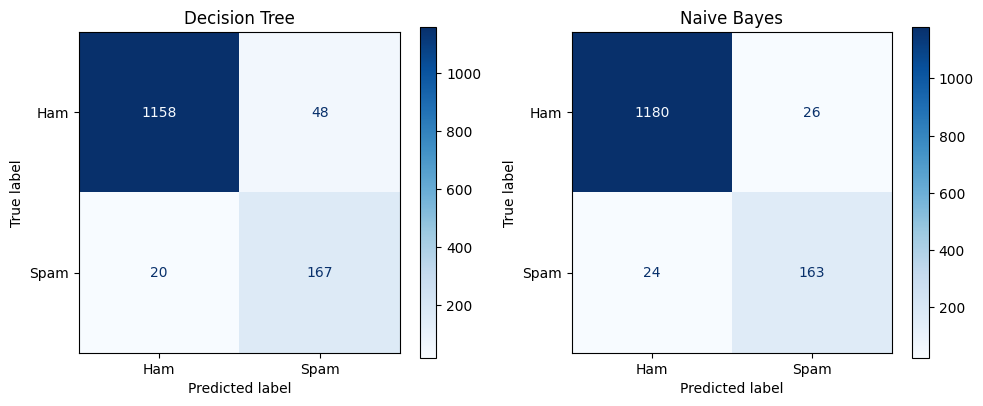

Decision Tree:
TP: 167, FP: 48, FN: 20, TN: 1158

Naive Bayes:
TP: 163, FP: 26, FN: 24, TN: 1180


In [ ]:
y_pred_dt = dt.predict(X_test)
y_pred_nb = nb.predict(X_test)

cm_dt = confusion_matrix(y_test, y_pred_dt)
cm_nb = confusion_matrix(y_test, y_pred_nb)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_dt,
    display_labels=['Ham', 'Spam'],
    ax=axes[0],
    cmap='Blues'
)
axes[0].set_title("Decision Tree")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_nb,
    display_labels=['Ham', 'Spam'],
    ax=axes[1],
    cmap='Blues'
)
axes[1].set_title("Naive Bayes")

plt.tight_layout()
plt.show()

tn_dt, fp_dt, fn_dt, tp_dt = cm_dt.ravel()
tn_nb, fp_nb, fn_nb, tp_nb = cm_nb.ravel()

print("Decision Tree:")
print(f"TP: {tp_dt}, FP: {fp_dt}, FN: {fn_dt}, TN: {tn_dt}")

print("\nNaive Bayes:")
print(f"TP: {tp_nb}, FP: {fp_nb}, FN: {fn_nb}, TN: {tn_nb}")

Step 6B

           Model  Accuracy  Precision    Recall  F1-Score
0  Decision Tree  0.951184   0.776744  0.893048  0.830846
1    Naive Bayes  0.964106   0.862434  0.871658  0.867021


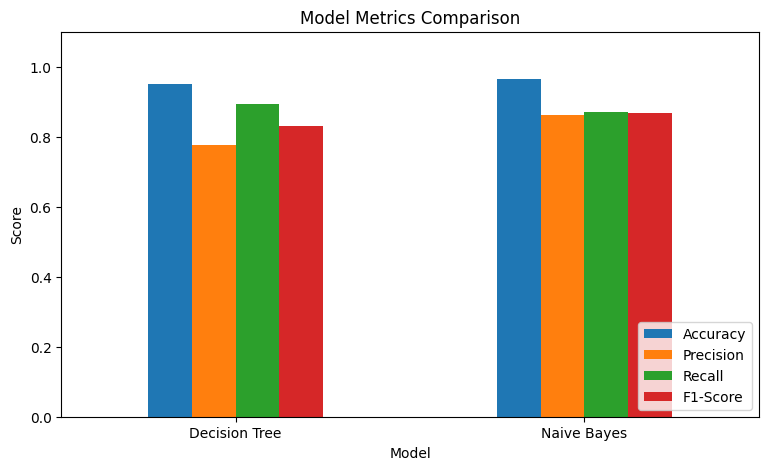

In [ ]:
results = {
    'Model': ['Decision Tree', 'Naive Bayes'],
    'Accuracy': [accuracy_score(y_test, y_pred_dt), accuracy_score(y_test, y_pred_nb)],
    'Precision': [precision_score(y_test, y_pred_dt), precision_score(y_test, y_pred_nb)],
    'Recall': [recall_score(y_test, y_pred_dt), recall_score(y_test, y_pred_nb)],
    'F1-Score': [f1_score(y_test, y_pred_dt), f1_score(y_test, y_pred_nb)]
}

df_metrics = pd.DataFrame(results)
print(df_metrics)

df_metrics.plot(x='Model', kind='bar', figsize=(9, 5), rot=0)
plt.title("Model Metrics Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.legend(loc='lower right')
plt.show()

Step 6C

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores_dt = cross_val_score(dt, X, y, cv=cv, scoring='f1')
scores_nb = cross_val_score(nb, X, y, cv=cv, scoring='f1')

print(f"Decision Tree Average F1: {scores_dt.mean():.4f}")
print(f"Naive Bayes Average F1:   {scores_nb.mean():.4f}")

Decision Tree Average F1: 0.8257
Naive Bayes Average F1:   0.8770


Q6a.

Decision Tree:


*   True Positives: 167
*   False Negatives: 20
*   False Positives: 48

Naive Bayes:

*   True Positives: 163
*   False Negatives: 24
*   False Positives: 26




Q6b.

Based on the question from Q1b, I chose the primary metric precision.

Naive Bayes wins by 0.0857 with a
precision of 0.8624 compared to Decision Tree's 0.7767.

The cross-validation result from step 6C doesn't exaclty confirm this. In that step, it evaluated the F1-score and not precision itself. However, it did confirm that Naive Bayes was a better model when it scored a higher F1 average across the board.

Q6c.

I recommend the Naive Bayes model for the spam filter. With its precision, it scored  more than 8% higher than the Decision Tree model. Though, it has its weakness and suffers a lower recall rate, allowing spam messages to be able to slip through. To improve this, we can adjust the classification probability and add additional features that can detect fraud patterns to reduce spam while being accurate.

Q6d.

1. has_phone

The has_phone feature fails as modern spam has progressed and rarely put phone numbers in the text. Instead, they direct you to web links. These types of texts would slip if it contains no phone number.

2. has_urgency

The has_urgency feature fails as early spammers often included scream words to scare the victim. Now, people have immediately identified them as scam, and scammers now use a more professional tone. If there are no urgency words, the scam would pass through the filter.

